# What skills do data roles actually demand?

First end-to-end answer from the pipeline: Adzuna postings → cleaned `jobs` table → dictionary skill extraction (`skill_hits`). This notebook ranks skills by **share of postings** that mention them and plots the top of that ranking.

In [1]:
import sqlite3
import sys
from pathlib import Path

import pandas as pd

# The notebook lives in notebooks/; the jobskills package sits one level up at
# the repo root. Put that root on sys.path so `import jobskills` resolves no
# matter where Jupyter was launched from.
REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from jobskills import config

# Pull the two analysis tables into pandas. skill_hits is one row per
# (posting, skill); jobs is one row per posting — we need both because the
# demand *share* divides hits by the total posting count.
with sqlite3.connect(config.SQLITE_PATH) as conn:
    hits = pd.read_sql_query("SELECT posting_id, skill, category FROM skill_hits", conn)
    jobs = pd.read_sql_query("SELECT id FROM jobs", conn)

n_postings = jobs["id"].nunique()
print(f"{len(hits)} skill hits across {n_postings} postings")
hits.head()

624 skill hits across 1389 postings


,posting_id,skill,category
0,5574048694,power bi,bi_tools
1,5574048689,power bi,bi_tools
2,5574048686,power bi,bi_tools
3,5574048688,power bi,bi_tools
4,5574048685,power bi,bi_tools


In [ ]:
# skill_hits is already deduped to one row per (posting, skill), so simply
# counting rows per skill == counting distinct postings that mention it.
# No nunique() needed: the UNIQUE(posting_id, skill) constraint from step 6
# guarantees a skill can't appear twice for the same posting.
demand = hits["skill"].value_counts()  # Series: skill -> posting count, desc

# Share of ALL postings (denominator = every posting in `jobs`, not just the
# subset with a match), expressed as a percent. This is the comparison-ready
# metric, computed off n_postings so it stays correct as snapshots change size.
demand = demand.rename("postings").to_frame()
demand["share_pct"] = demand["postings"] / n_postings * 100

demand.head(10)

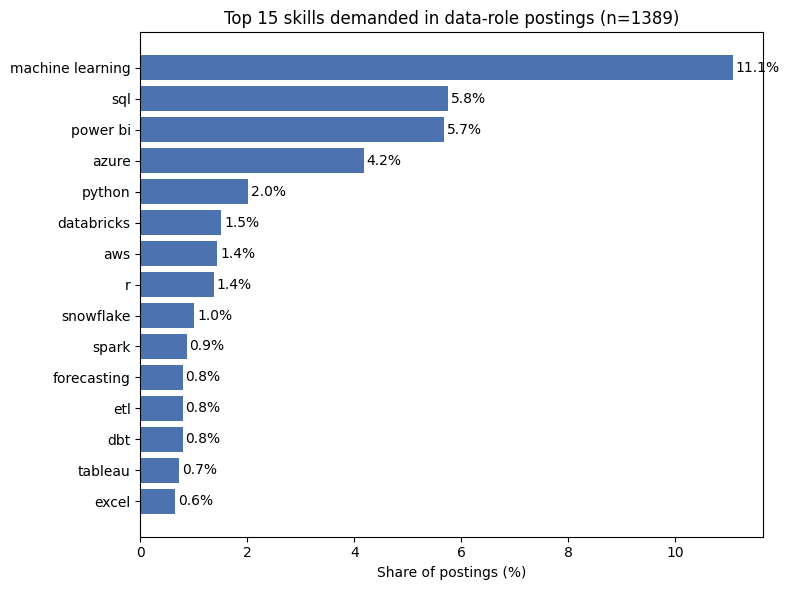

In [3]:
import matplotlib.pyplot as plt

TOP_N = 15
top = demand.head(TOP_N)  # already sorted desc by value_counts()

fig, ax = plt.subplots(figsize=(8, 6))

# Drive bars + text off numeric y-positions, not the skill strings. ax.text at
# a *string* y-position trips matplotlib's category converter (returns a 1-elem
# array -> float() error), so we place everything at integers 0..N-1 and hang
# the skill names on the ticks instead.
y_pos = range(len(top))
ax.barh(list(y_pos), top["share_pct"], color="#4C72B0")
ax.set_yticks(list(y_pos))
ax.set_yticklabels(top.index)

# barh draws position 0 at the BOTTOM; invert so the ranking reads top-down.
ax.invert_yaxis()

ax.set_xlabel("Share of postings (%)")
ax.set_title(f"Top {TOP_N} skills demanded in data-role postings (n={n_postings})")

# Label each bar with its exact percentage so the reader needn't eyeball the axis.
for y, share in zip(y_pos, top["share_pct"]):
    ax.text(share + 0.05, y, f"{share:.1f}%", va="center")

fig.tight_layout()
plt.show()


## What this first cut shows

**Question:** across continental-European data-role postings (Germany, Switzerland, Spain — data analyst, data scientist, BI analyst, analytics engineer, BI developer), which skills are asked for most often?

**Read:** of 1,389 postings (DE 735 / ES 464 / CH 190), the most-demanded skills are **machine learning, SQL, Power BI, and Azure**, followed by cloud/warehouse tooling (Databricks, AWS, Snowflake, Spark) and Python. The ranking is by *share of postings* — the percent of all postings whose title or description mentions the skill — so it stays comparable when later snapshots scrape a different number of postings.

**Honest caveat — two compounding gaps:** only ~24% of postings matched *any* skill in the current taxonomy, so absolute shares are low. Part of that is the usual **coverage gap** (the hand-curated `skills.yaml` doesn't yet know every term), but part is a **language gap**: roughly half these postings are in German or Spanish, and an English-only keyword taxonomy under-matches them (match rate CH 33% vs DE 23% / ES 22%). The `n` denominator (1,389) keeps the percentages truthful rather than inflating them off the matched subset. Closing both gaps is M3 work — n-gram mining for coverage, German/Spanish aliases for language.

*Single Adzuna snapshot across three country boards; a starting baseline, not a final read on the market. Pan-European **remote** coverage arrives with the M2 remote boards — note this snapshot's `remote` tag is mostly `unknown`, partly because the remote regex is also English-only.*